# Reading a recording back out of NWB

A recording is a CSV of channels and a sidecar. This notebook converts one to NWB, reads it
back, and looks at the signal in the units NWB reports. The point is the round trip: what goes
in comes out as the same numbers, with the metadata the sidecar carried.

Needs a recording. If `code/recordings/` is empty, run `python code/get_example_data.py` first
to pull PiEEG's own example data.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO

sys.path.insert(0, str(Path("code").resolve()))
from mission_3_nwb import csv_to_nwb
from spectrum import load

csv_path = Path("code/recordings/example_alpha.csv")
assert csv_path.exists(), "run python code/get_example_data.py first"
print("recording:", csv_path, f"({csv_path.stat().st_size / 1e6:.1f} MB)")

recording: code\recordings\example_alpha.csv (0.8 MB)


In [2]:
# Convert, then read the file back the way any other tool would
nwb_path = csv_to_nwb(csv_path, Path("code/nwb"))
io = NWBHDF5IO(nwb_path, "r")
nwb = io.read()
series = nwb.acquisition["eeg"]
print("session:   ", nwb.session_description)
print("start:     ", nwb.session_start_time)
print("subject:   ", nwb.subject.subject_id, "| sex", nwb.subject.sex, "| age", nwb.subject.age)
print("channels:  ", series.data.shape[1], "at", series.rate, "Hz")
print("stored as: ", series.data[:].dtype, "| conversion", series.conversion, "-> reports", series.unit)
print("electrodes:", list(nwb.electrodes["location"]))
if "invalid_times" in nwb.intervals:
    rows = nwb.intervals["invalid_times"]
    print("ranges to skip:", len(rows))

session:   

 Recording used by PiEEG's own alpha plotting example (1.GUI/dataset/2.Alpha_plot.py) (start time unknown: set to the conversion time)
start:      2026-11-02 00:38:47.400192+00:00
subject:    PiEEG example subject | sex U | age /
channels:   8 at 250.0 Hz
stored as:  float64 | conversion 1e-06 -> reports volts
electrodes: ['not documented', 'not documented', 'not documented', 'not documented', 'not documented', 'not documented', 'not documented', 'not documented']


In [3]:
# The numbers survive the round trip: the file reports volts, the CSV held microvolts
data_uv = np.column_stack([load(csv_path, c) for c in range(1, series.data.shape[1] + 1)])
back = series.data[:] * series.conversion
print("largest difference:", float(np.abs(back - data_uv * 1e-6).max()), "volts")

largest difference: 0.0 volts


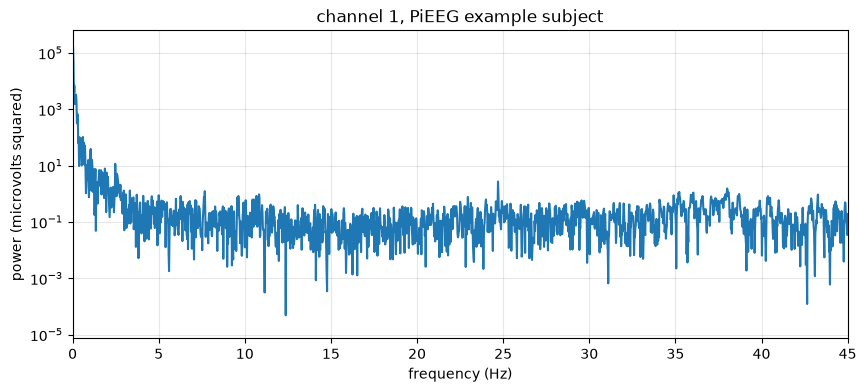

In [4]:
# One channel's spectrum, in microvolts so the numbers match what the CSV holds
ch = 0
signal_uv = back[:, ch] * 1e6
fs = series.rate
window = np.hanning(len(signal_uv))
spectrum = np.fft.rfft(signal_uv * window)
freqs = np.fft.rfftfreq(len(signal_uv), d=1 / fs)
power = (np.abs(spectrum) * 2 / window.sum()) ** 2

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(freqs, power)
ax.set(xlabel="frequency (Hz)", ylabel="power (microvolts squared)",
       title=f"channel {ch + 1}, {nwb.subject.subject_id}")
ax.set_xlim(0, 45)
ax.grid(alpha=0.3)
plt.show()

In [5]:
io.close()
print("the notebook read a NWB file, checked the numbers and closed it cleanly")

the notebook read a NWB file, checked the numbers and closed it cleanly
